Why are we using DiD here? We are analyzing a rollout that already happened. Regional teams chose which markets received the tool, so there is no randomized control group. DiD uses markets without the tool to estimate how orders might have changed without the launch. Its credibility depends on those markets providing a believable comparison.

If we plan another rollout, it could randomize access. Because promotion may shift customer demand between nearby stores/orders, randomizing markets may be more appropriate than randomizing indvidual. 

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

#### Inspect the market trends before estimating the effect

In [2]:
rng = np.random.default_rng(31)
markets = [f"Market {i + 1}" for i in range(20)]
market_base = rng.normal(20, 2, len(markets))
market_growth = rng.normal(0, 0.025, len(markets))
rows = []

for i, market in enumerate(markets):
    treated = int(i < 10)
    for week in range(24):
        post = int(week >= 12)
        # Every market shares a gradual trend and a seasonal pattern.
        shared_pattern = 0.12 * week + 0.6 * np.sin(2 * np.pi * week / 12)
        orders = (market_base[i] + shared_pattern + market_growth[i] * week
                  + 2.4 * treated * post + rng.normal(0, 0.55))
        rows.append([market, week, treated, post, orders])

panel = pd.DataFrame(rows, columns=[
    "market", "week", "treated", "post", "orders_per_100"
])

# Print raw market-week rows before calculating group averages.
print("First eight market-week rows:")
print(panel.head(8).round(3).to_string(index=False))


First eight market-week rows:
  market  week  treated  post  orders_per_100
Market 1     0        1     0          18.037
Market 1     1        1     0          19.510
Market 1     2        1     0          20.298
Market 1     3        1     0          19.911
Market 1     4        1     0          20.400
Market 1     5        1     0          19.410
Market 1     6        1     0          19.173
Market 1     7        1     0          19.280


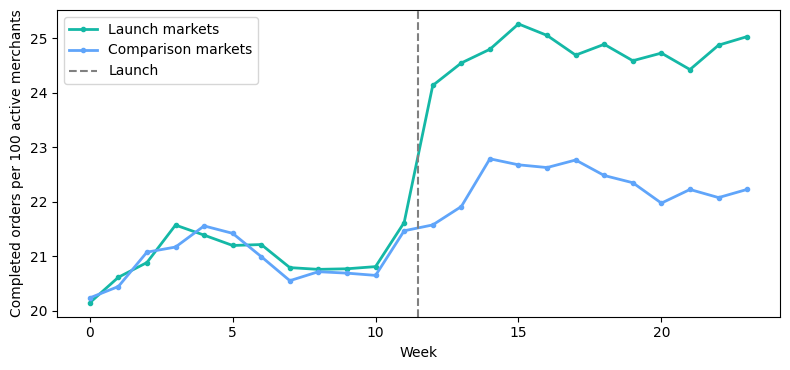

In [3]:
# Plot weekly group averages. The vertical line marks the first treated week.
trend = panel.groupby(["week", "treated"], as_index=False)[
    "orders_per_100"
].mean()
fig, ax = plt.subplots(figsize=(8, 3.8))
for treated, label, color in [(1, "Launch markets", "#14b8a6"),
                              (0, "Comparison markets", "#60a5fa")]:
    group = trend[trend["treated"] == treated]
    ax.plot(group["week"], group["orders_per_100"], marker="o",
            markersize=3, linewidth=2, label=label, color=color)
ax.axvline(11.5, color="gray", linestyle="--", label="Launch")
ax.set(xlabel="Week", ylabel="Completed orders per 100 active merchants")
ax.legend()
fig.tight_layout()

In [4]:
# Collapse the panel into the four averages used by the DiD calculation.
panel["group"] = np.where(panel["treated"] == 1,
                          "Launch markets", "Comparison markets")
panel["period"] = np.where(panel["post"] == 1, "After", "Before")
averages = panel.groupby(["group", "period"])["orders_per_100"].mean().unstack()
averages["Change"] = averages["After"] - averages["Before"]
did = (averages.loc["Launch markets", "Change"]
       - averages.loc["Comparison markets", "Change"])

print("\nGroup averages:")
print(averages.round(3).to_string())
print(f"\nDiD estimate: {did:.3f} orders per 100 active merchants")


Group averages:
period               After  Before  Change
group                                     
Comparison markets  22.310  20.917   1.393
Launch markets      24.756  20.984   3.772

DiD estimate: 2.379 orders per 100 active merchants


The raw preview shows the unit of analysis: one market in one week. The chart then averages those rows within each group so we can see the shared movement and the separation after week 12.

Launch markets rise from 20.984 to 24.756 orders per 100 active merchants, a gain of 3.772. Comparison markets rise from 20.917 to 22.310, a gain of 1.393. Subtracting the two changes gives 2.379 additional orders per 100 active merchants.

The data setup was built with a true effect of 2.4. The estimate is slightly different because the market outcomes include random variation and small differences in growth. With real data, the true effect would be unknown.

#### Fit the DiD Regression

In [10]:
# Simulate 20 markets observed for 24 weeks.
rng = np.random.default_rng(31)
markets = [f"Market {i + 1}" for i in range(20)]
market_base = rng.normal(20, 2, len(markets))
market_growth = rng.normal(0, 0.025, len(markets))
rows = []

for i, market in enumerate(markets):
    treated = int(i < 10)
    for week in range(24):
        post = int(week >= 12)
        shared_pattern = 0.12 * week + 0.6 * np.sin(2 * np.pi * week / 12)
        outcome = (
            market_base[i]
            + shared_pattern
            + market_growth[i] * week
            + 2.4 * treated * post
            + rng.normal(0, 0.55)
        )
        rows.append([market, week, treated, post, outcome])

panel = pd.DataFrame(
    rows,
    columns=["market", "week", "treated", "post", "orders_per_100"],
)

# Market effects absorb stable market differences.
# Week effects absorb changes shared by every market.
# Clustered standard errors allow observations in one market to be related.
model = smf.ols(
    "orders_per_100 ~ treated:post + C(market) + C(week)",
    data=panel,
).fit(cov_type="cluster", cov_kwds={"groups": panel["market"]})

print(model.summary(alpha=0.05))

                            OLS Regression Results                            
Dep. Variable:         orders_per_100   R-squared:                       0.950
Model:                            OLS   Adj. R-squared:                  0.945
Method:                 Least Squares   F-statistic:                     133.0
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.77e-16
Time:                        20:59:45   Log-Likelihood:                -393.44
No. Observations:                 480   AIC:                             874.9
Df Residuals:                     436   BIC:                             1059.
Df Model:                          43                                         
Covariance Type:              cluster                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 18

What did we find? Read the treated:post row. The coefficient is 2.379, so the model reaches the same estimate as the four-average calculation: about 2.4 additional completed orders per 100 active merchants in the launch markets after access began.

How sure are we? The cluster-based standard error is 0.191, and the 95% confidence interval runs from 2.004 to 2.753. The two-sided p-value is below 0.001, so the interval excludes zero at the 5% significance level. Clustering by market allows weekly outcomes from the same market to be related.

What do the other fields mean? The market coefficients capture stable level differences, and the week coefficients capture shared calendar changes. The model's R² is about 0.950, largely because those fixed effects explain persistent differences and common weekly movement. The overall F-test asks whether the included terms jointly predict orders. Neither measure tells us that the launch caused the remaining gap.

The interval measures sampling uncertainty under this model. With only 20 markets, it is still an approximate measure. More importantly, it cannot tell us whether another event affected only the launch markets. That is why the design checks come next.

#### Test the comparison before Making the decision

The estimate is commercially interesting, but it is causal only if the comparison markets show what would have happened without the tool. We will test two warning signs: whether the groups had different slopes before launch and whether DiD finds a false effect at an earlier placebo date.

,Diagnostic,Estimate,Standard error
0,Prelaunch slope difference,0.015,0.026
1,Placebo DiD at week 8,0.064,0.184


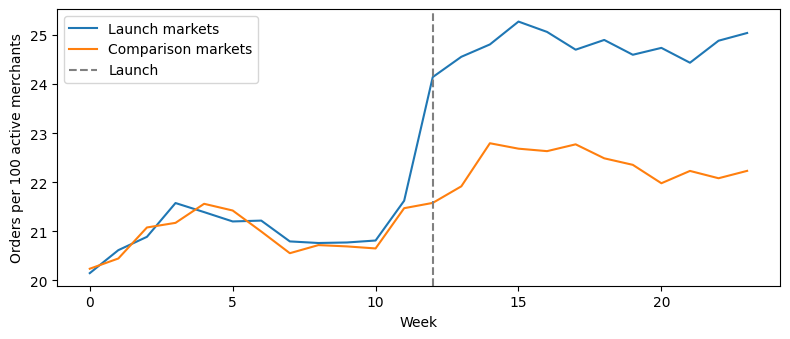

In [11]:
# Recreate the same case-study panel.
rng = np.random.default_rng(31)
markets = [f"Market {i + 1}" for i in range(20)]
market_base = rng.normal(20, 2, len(markets))
market_growth = rng.normal(0, 0.025, len(markets))
rows = []
for i, market in enumerate(markets):
    treated = int(i < 10)
    for week in range(24):
        post = int(week >= 12)
        shared_pattern = 0.12 * week + 0.6 * np.sin(2 * np.pi * week / 12)
        outcome = (market_base[i] + shared_pattern + market_growth[i] * week
                   + 2.4 * treated * post + rng.normal(0, 0.55))
        rows.append([market, week, treated, post, outcome])
panel = pd.DataFrame(rows, columns=[
    "market", "week", "treated", "post", "orders_per_100"
])

# Show the average path for each group.
trend_data = panel.groupby(["week", "treated"], as_index=False)[
    "orders_per_100"
].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
for treated, label in [(1, "Launch markets"), (0, "Comparison markets")]:
    group = trend_data[trend_data["treated"] == treated]
    ax.plot(group["week"], group["orders_per_100"], label=label)
ax.axvline(12, color="gray", linestyle="--", label="Launch")
ax.set(xlabel="Week", ylabel="Orders per 100 active merchants")
ax.legend()
fig.tight_layout()

# Estimate any difference in the PRE-launch slopes.
pre = panel[panel["week"] < 12].copy()
pretrend = smf.ols(
    "orders_per_100 ~ week + treated:week + C(market)", data=pre
).fit(cov_type="cluster", cov_kwds={"groups": pre["market"]})

# Pretend the launch happened at week 8, while keeping only prelaunch data.
pre["placebo_post"] = (pre["week"] >= 8).astype(int)
placebo = smf.ols(
    "orders_per_100 ~ treated:placebo_post + C(market) + C(week)",
    data=pre,
).fit(cov_type="cluster", cov_kwds={"groups": pre["market"]})

pd.DataFrame({
    "Diagnostic": ["Prelaunch slope difference", "Placebo DiD at week 8"],
    "Estimate": [pretrend.params["treated:week"],
                 placebo.params["treated:placebo_post"]],
    "Standard error": [pretrend.bse["treated:week"],
                       placebo.bse["treated:placebo_post"]],
}).round(3)

The estimated prelaunch slope difference is 0.015 orders per 100 merchants per week, with a standard error of 0.026. The placebo estimate is 0.064, with a standard error of 0.184. Neither diagnostic shows a clear earlier divergence in this simulation.

That is reassuring, not conclusive. Similar earlier trends cannot prove the trends would have stayed parallel after launch. We still need to check market selection, overlapping promotions, spillovers, metric changes, and whether the result holds under reasonable specifications.

The estimated gain clears zero, but a launch decision also needs a business threshold. If 2.379 extra orders per 100 merchants covers product and incentive costs while cancellations and support contacts stay acceptable, the result supports a limited expansion. Randomizing the next wave would give stronger evidence for the broader rollout.